# IBM's Relay-BP repository

**What it is.** IBM Quantum's open-source decoder for quantum LDPC codes, with the Stim circuits and the
results behind their paper.
- Repo: https://github.com/trmue/relay (Apache-2.0)
- Paper: Müller et al., *Improved belief propagation is sufficient for real-time decoding of quantum memory*,
  [arXiv:2506.01779](https://arxiv.org/abs/2506.01779)

**Why we use it.** Its gross code circuits ([[144,12,12]], the code in Bravyi et al., *Nature* 627, 778, 2024)
are the circuits our gross code runs are built on, and its decoder settings are the ones we copied.

**Plan of this notebook**

| Step | What we do | Graph |
|---|---|---|
| 1 | Get the repo and the package | – |
| 2 | Look at what is inside | circuits per code |
| 3 | The idea in five lines | circuit picture |
| 4 | IBM's smallest example: a 3-bit repetition code | which errors get corrected |
| 5 | Load IBM's circuits and compare their sizes | size chart, gate timeline |
| 6 | Why IBM keeps only the Z detectors | detector split, IBM's own data |
| 7 | Run: surface code with PyMatching | error rate vs noise, threshold |
| 8 | Run: BB codes with Relay-BP, and the gross code against IBM's results | error rate vs noise |
| 9 | What we take from this repo | – |


## Setup

Run once in a fresh environment (Python 3.12 recommended). The versions are the ones the results were produced with.

In [1]:
%pip install -q stim==1.16.0 sinter==1.15.0 pymatching==2.4.0 stabilizer-qec==2.1.0 "numpy>=2.0,<2.3" scipy pandas matplotlib
# IBM's own Relay-BP decoder. PyPI has a ready-made install for Linux only; on Windows and macOS this builds it
# from source, which needs the Rust compiler (https://rustup.rs). If it fails, the notebook uses stabilizer-qec's
# RelayBp (a separate implementation of the same algorithm) and says so.
%pip install -q "relay-bp[stim]"

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### Code and data used from this folder

Functions that several notebooks share are kept in `helpers/` rather than repeated in every notebook; they are
imported from there below. Each file is commented and can be read on its own.

| File | What it is for | Used here |
|---|---|---|
| `helpers/tour_helpers.py` | plotting, tables, running and caching experiments | `catalogue`, `circuit_summary`, `collect`, `get_repo`, `ibm_data`, `plot_catalogue`, `plot_detector_split`, `plot_gate_counts`, `plot_ler`, `plot_repetition`, `plot_rounds`, `plot_summary`, `relay_installed`, `repetition_fallback`, `savefig`, `select`, `show_head` |
| IBM's repo (`~/relay`, cloned on first use) | IBM's own test helpers | `testdata.get_test_circuit`, `testdata.filter_detectors_by_basis` |

Folders read or written:
- `data/`: saved results and IBM's circuits
- `results/`: cached runs (re-used, not re-run)
- `figures/`: PNG files written by this notebook

## Step 1 · Get the repo and the package

The repo is cloned into `~/relay` (a folder called `relay` in the user's home folder) on first use, about 110 MB,
almost all of it Stim circuit files. It is not cloned next to this notebook because Windows limits file paths to
260 characters and IBM's circuit file names are up to 139 characters long. Cloning needs `git`.

The decoder itself is the `relay_bp` Python package (written in Rust):

    pip install "relay-bp[stim]"

On Windows this builds from source and needs the Rust compiler once (https://rustup.rs). If it is not
installed, the notebook uses `stabilizer-qec`'s `RelayBp`, a separate implementation of the same algorithm,
and says so when it runs.

In [2]:
import sys; sys.path.insert(0, "helpers")    # helper functions (see "Code and data used" above)
import numpy as np, matplotlib.pyplot as plt, stim, sinter
import tour_helpers as tour

REPO = tour.get_repo()   # clones https://github.com/trmue/relay into <home>/relay the first time
print("repo:", REPO)
print("IBM relay_bp installed:", tour.relay_installed())

repo: C:\Users\kanis\relay
IBM relay_bp installed: True


In [3]:
# IBM's own helpers, imported exactly as IBM's GettingStarted notebook does
from testdata import get_test_circuit, filter_detectors_by_basis

## Step 2 · What is inside the repo

| Folder | What it holds |
|---|---|
| `src/`, `crates/` | the decoder, written in Rust |
| `python/relay_bp/` | the Python package: decoders, Stim and Sinter glue |
| `examples/` | three IBM notebooks (GettingStarted, BB code analysis, surface code analysis) |
| `examples/data/` | **IBM's published results** as Sinter CSV files — we plot these below |
| `tests/testdata/` | **672 ready-made Stim circuits** — the part we use most |

Each circuit file name says what it is, for example
`circuit=rotated_surface_code_memory_Z,distance=5,rounds=5,error_rate=0.003,noise_model=uniform_circuit,...`

672 circuits; noise levels p: [0.001, 0.0015, 0.002, 0.0025, 0.003, 0.0035, 0.004, 0.0045, 0.005, 0.006, 0.007, 0.008, 0.009, 0.01]


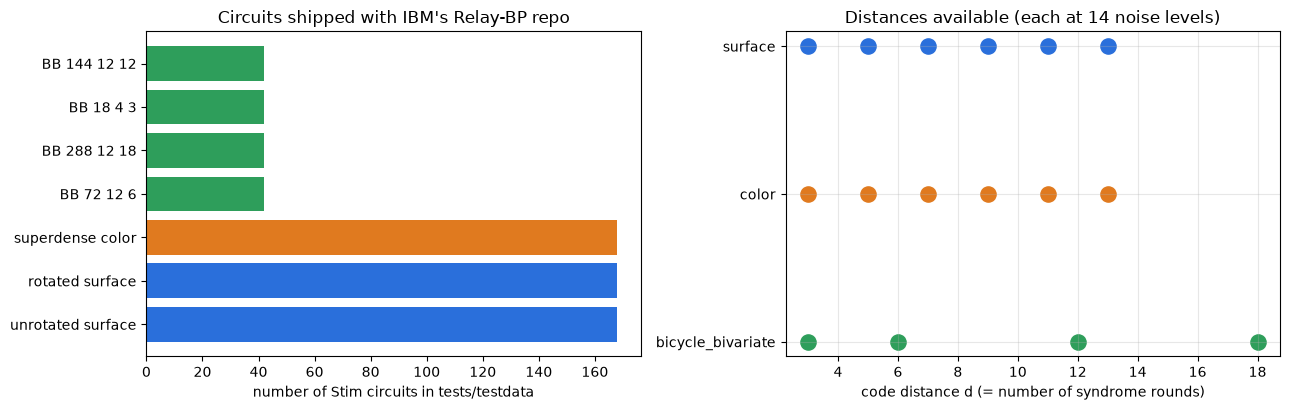

In [4]:
cat = tour.catalogue(REPO)
print(len(cat), "circuits;", "noise levels p:", [float(p) for p in sorted(cat.p.unique())])
tour.plot_catalogue(cat)

**What the graph shows.** Three code families: surface codes (rotated and unrotated, d = 3 to 13), color codes
(d = 3 to 13) and bivariate bicycle (BB) codes, of which the gross code [[144,12,12]] is one. Every circuit
is a *memory experiment*: prepare the logical qubits, run d rounds of syndrome measurement, measure.

There is **no repetition-code circuit** in the repo. IBM's only repetition code is the 3-bit toy example
in their GettingStarted notebook, which we use in Step 4.

## Step 3 · The idea in five lines

1. A **memory experiment** stores logical qubits for some rounds while noise acts on every gate.
2. Each round measures the **checks** (stabilizers). A **detector** is a check whose outcome changed
   between two rounds — it lights up when an error happened nearby.
3. Stim turns the noisy circuit into a **detector error model (DEM)**: a list of every possible fault, its
   probability, which detectors it lights up, and whether it flips a logical qubit.
4. A **decoder** looks only at the lit detectors and guesses whether the logical qubits were flipped.
5. A shot **fails** if the guess is wrong. The **logical error rate** is the fraction of failed shots.

Below is IBM's smallest stored circuit, the d = 3 rotated surface code, drawn by Stim at one time step: the
qubits and the gates in each time step of one syndrome round: reset, four layers of CX gates (the
diagonal lines), Hadamards, and the measurement of the check qubits. Noise is left out of the picture.

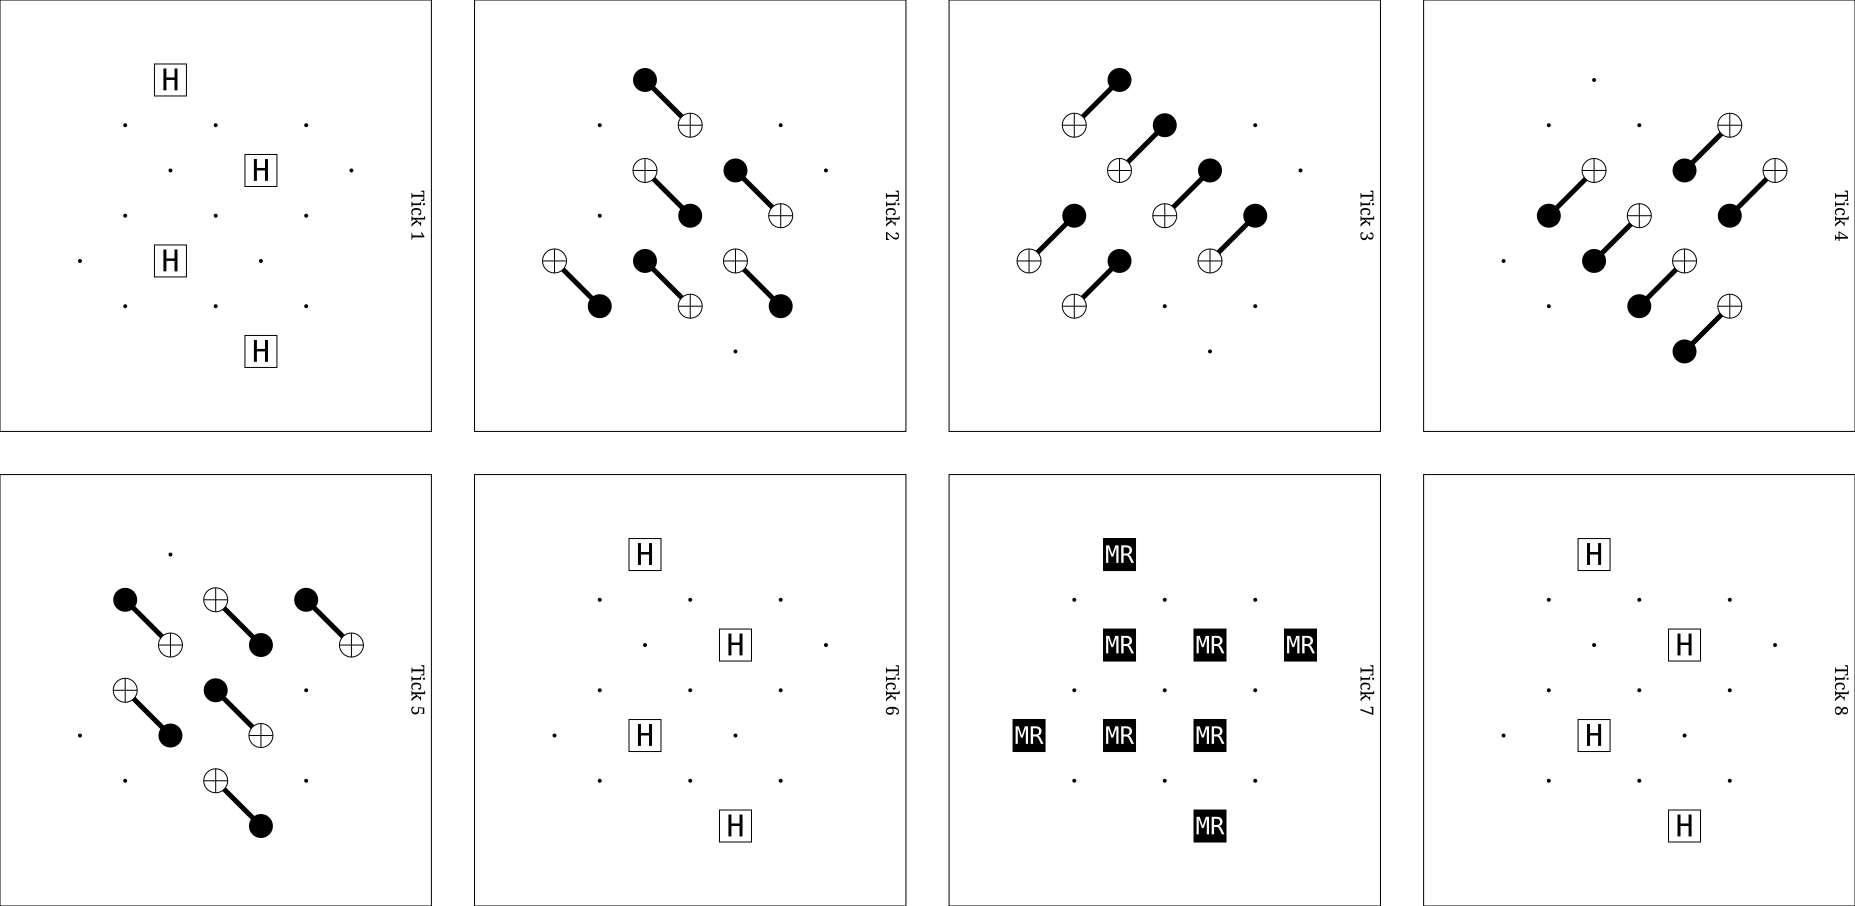

In [5]:
surf3 = get_test_circuit("rotated_surface_code_memory_Z", distance=3, rounds=3, error_rate=0.003)
surf3.without_noise().diagram("timeslice-svg", tick=range(1, 9), rows=2)   # time steps 1-8 = one syndrome round

## Step 4 · IBM's smallest example: a 3-bit repetition code

Taken from IBM's `examples/GettingStarted.ipynb`. Three bits, two checks: check 1 compares bits 1 and 2,
check 2 compares bits 2 and 3. Each bit flips with probability 0.003. We try all 8 possible error patterns
and ask the decoder to correct each one.

Expected: the decoder corrects any **single** flip; two or three flips look like a different single flip, so
those fail. That is the distance-3 limit.

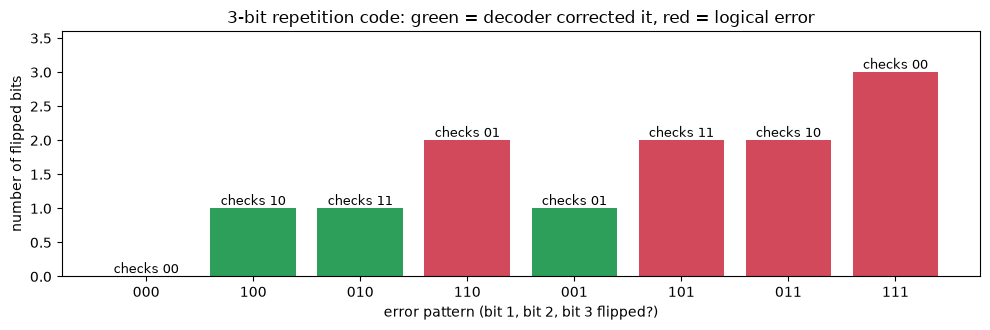

In [6]:
from scipy.sparse import csr_matrix

H = csr_matrix(np.array([[1, 1, 0],          # check 1: bit 1 + bit 2
                         [0, 1, 1]]))        # check 2: bit 2 + bit 3
priors = np.full(3, 0.003)                   # flip probability of each bit
L = np.array([[1, 1, 1]], dtype=np.uint8)    # the logical bit: parity of all three

errors = np.array([[(i >> b) & 1 for b in range(3)] for i in range(8)], dtype=np.uint8)  # all 8 patterns
syndromes = ((errors @ H.toarray().T) % 2).astype(np.uint8)   # what the two checks report

if tour.relay_installed():
    import relay_bp
    # IBM's decoder and settings, as in GettingStarted.ipynb
    dec = relay_bp.RelayDecoderF32(H, error_priors=priors, gamma0=0.1, pre_iter=80, num_sets=100,
                                   set_max_iter=60, gamma_dist_interval=(-0.24, 0.66), stop_nconv=5)
    guessed_errors = dec.decode_batch(syndromes)
    guessed_flip = (guessed_errors @ L.T % 2).ravel()       # did the decoder think the logical bit flipped?
else:
    guessed_flip = tour.repetition_fallback(syndromes)      # same problem through stabilizer-qec

true_flip = (errors @ L.T % 2).ravel()                      # did the logical bit really flip?
tour.plot_repetition(errors, syndromes, guessed_flip == true_flip)

## Step 5 · Load IBM's circuits and compare their sizes

Four of IBM's Z-memory circuits at p = 0.003: the surface code d = 3, and three BB codes. The number of rounds
equals the distance, as in IBM's files.

,qubits,two-qubit gates,measurements,detectors,logical observables,error mechanisms (DEM)
circuit,,,,,,
surface d=3,26,72,33,24,1,219
"BB [[18,4,3]]",36,324,72,54,4,1800
"BB [[72,12,6]]",144,2592,504,432,12,16164
"gross [[144,12,12]]",288,10368,1872,1728,12,67752


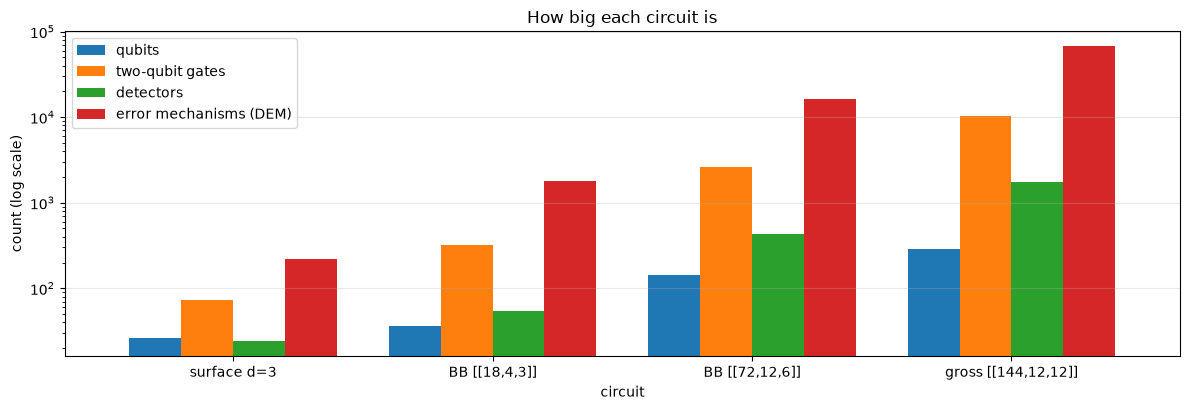

In [7]:
P = 0.003
circuits = {
    "surface d=3":        get_test_circuit("rotated_surface_code_memory_Z",       distance=3,  rounds=3,  error_rate=P),
    "BB [[18,4,3]]":      get_test_circuit("bicycle_bivariate_18_4_3_memory_Z",   distance=3,  rounds=3,  error_rate=P),
    "BB [[72,12,6]]":     get_test_circuit("bicycle_bivariate_72_12_6_memory_Z",  distance=6,  rounds=6,  error_rate=P),
    "gross [[144,12,12]]": get_test_circuit("bicycle_bivariate_144_12_12_memory_Z", distance=12, rounds=12, error_rate=P),
}
summary = tour.circuit_summary(circuits)
display(summary)
tour.plot_summary(summary)

**What the graph shows.** Compared with the d = 3 surface code, the gross code circuit has about 11× more
qubits (144 data + 144 check), about 140× more two-qubit gates and about 300× more possible faults. It
stores 12 logical qubits (the "logical observables" column) where the surface code stores 1.

The next graph walks through the gross code file from start to end. Each syndrome round adds the same
number of CX gates and ends with a measurement of the check qubits (orange lines).

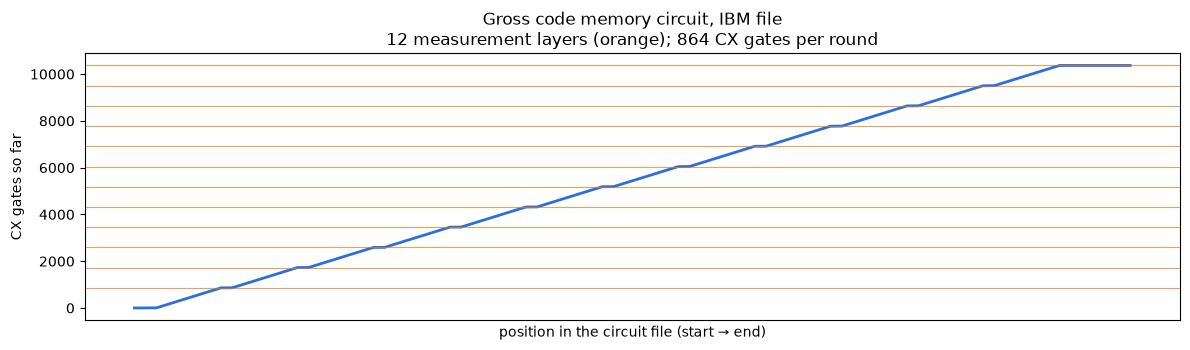

In [8]:
tour.plot_rounds(circuits["gross [[144,12,12]]"], "Gross code memory circuit, IBM file")

### Inside the gross code file

The circuit is plain text. The first 576 lines reset the 288 qubits (each reset followed by its error); the
lines below are where round 1's CX gates begin. Each `CX a b` is followed by `DEPOLARIZE2(p) a b`, the noise
on that gate.

In [9]:
gross = circuits["gross [[144,12,12]]"]
tour.show_head(gross, 12, start="CX")

... (lines 1-576 skipped)
CX 72 234
DEPOLARIZE2(0.003) 72 234
CX 73 235
DEPOLARIZE2(0.003) 73 235
CX 74 236
DEPOLARIZE2(0.003) 74 236
CX 75 237
DEPOLARIZE2(0.003) 75 237
CX 76 238
DEPOLARIZE2(0.003) 76 238
CX 77 239
DEPOLARIZE2(0.003) 77 239
... (26411 lines in total)


Counting every operation in the file: the gates (CX, resets R/RX, measurements M/MX), the noise channels
that follow them, and the detectors and logical observables that tell the decoder what to check.

qubits: 288   detectors: 1728   logical observables: 12


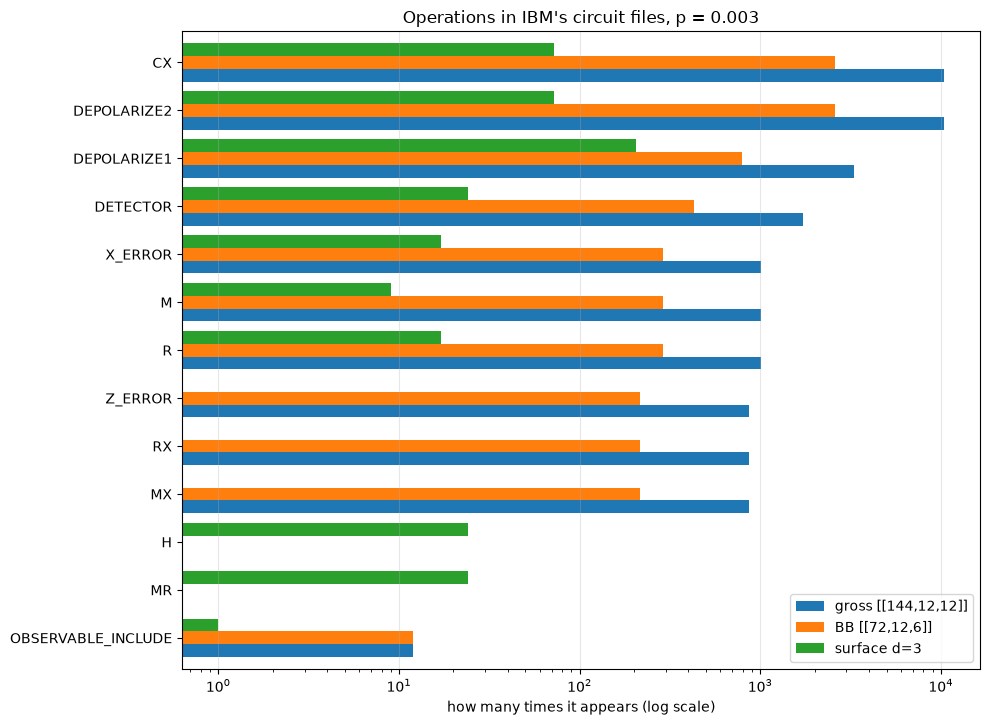

In [10]:
print(f"qubits: {gross.num_qubits}   detectors: {gross.num_detectors}   logical observables: {gross.num_observables}")
tour.plot_gate_counts({"gross [[144,12,12]]": gross, "BB [[72,12,6]]": circuits["BB [[72,12,6]]"],
                       "surface d=3": circuits["surface d=3"]}, "Operations in IBM's circuit files, p = 0.003");

**Reading it.** 10,368 CX gates = 144 checks × 6 CX × 12 rounds. 1,728 detectors = 144 checks × 12 rounds.
The noise lines (DEPOLARIZE2, DEPOLARIZE1, X_ERROR, Z_ERROR) sit next to the operation they disturb; that is
the "uniform circuit noise" model: every operation fails with the same probability p.

## Step 6 · Why IBM keeps only the Z detectors

IBM's GettingStarted notebook does this before decoding:

```python
bb_circuit = filter_detectors_by_basis(bb_circuit, "Z")
```

**The reason.** In a Z-memory experiment the logical qubits are read out in the Z basis. Only **X errors** can
flip a Z readout. X errors are seen only by the **Z-type checks**. The X-type checks see Z errors, which never
change the answer. So the X-type detectors can be dropped and the decoder solves a problem half the size.
This is "decoding X and Z separately", the usual way to decode CSS codes.

The cost: a Y error is an X and a Z at once. Dropping the X-type detectors throws away that link. IBM's
notebook says keeping everything ("XYZ decoding") can help Relay-BP; BP-OSD is only run on the filtered
version in their notebooks.

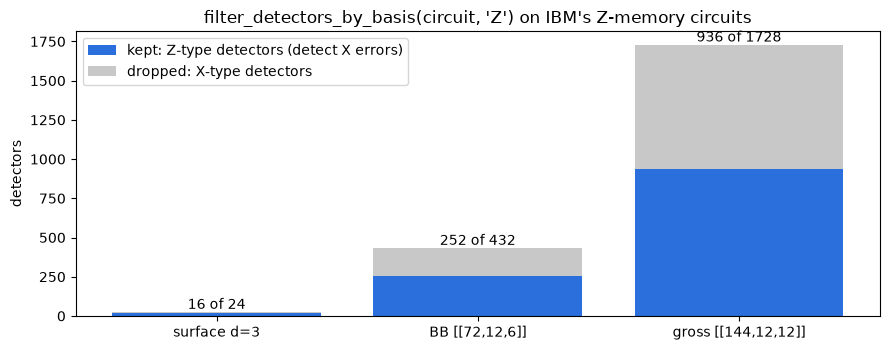

In [11]:
rows = []
for name in ["surface d=3", "BB [[72,12,6]]", "gross [[144,12,12]]"]:
    c = circuits[name]
    rows.append((name, c.num_detectors, filter_detectors_by_basis(c, "Z").num_detectors))
tour.plot_detector_split(rows, save="detector_split.png")

**What the graph shows.** Roughly half the detectors are kept. For the gross code the last round keeps
extra Z detectors that are built from the final data-qubit readout.

**IBM's own data on this choice.** IBM's published gross code results (`examples/data/`) contain both
versions for Relay-BP. Plotted directly from their CSV:

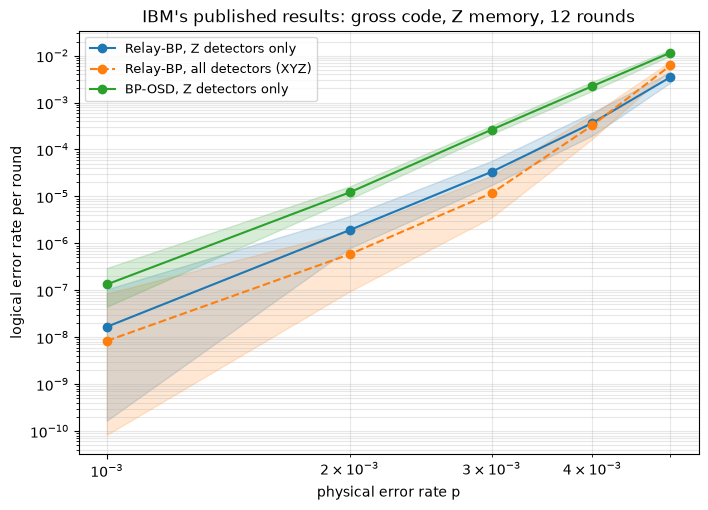

In [12]:
ibm_gross = tour.ibm_data(REPO, "bicycle_bivariate_144_12_12_fine_ler_sweep.csv")
tour.plot_ler({
    "Relay-BP, Z detectors only": tour.select(ibm_gross, decoder="relay-bp", basis="Z", xyz=False),
    "Relay-BP, all detectors (XYZ)": tour.select(ibm_gross, decoder="relay-bp", basis="Z", xyz=True),
    "BP-OSD, Z detectors only": tour.select(ibm_gross, decoder="bp-osd", basis="Z", xyz=False),
}, "IBM's published results: gross code, Z memory, 12 rounds",
   styles={"Relay-BP, all detectors (XYZ)": {"linestyle": "--"}})
tour.savefig("ibm_published_decoders.png"); plt.show()

**What the graph shows.** At low noise (p ≤ 0.003) Relay-BP with all detectors is 2–3× better than with
Z detectors only, because it uses the Y-error link. At p = 0.005 it is worse. BP-OSD on Z detectors is
the reference IBM compares against; Relay-BP beats it at every p. Our own gross code runs used the
**Z-detectors-only** version with BP-OSD, i.e. the bottom-right reference curve.

## Step 7 · Run: surface code with PyMatching

Our first own run on IBM's circuits. The surface code is the baseline the gross code is compared against.

- **Decoder:** PyMatching (minimum-weight matching), the standard surface code decoder.
- **Distances:** 3, 5, 7. Bigger codes should do better below the threshold and worse above it.
- **Noise:** p from 0.003 to 0.01, IBM's uniform circuit noise.
- **Shots:** stop at 100,000 shots or 300 failures, whichever comes first. A few minutes on a laptop.

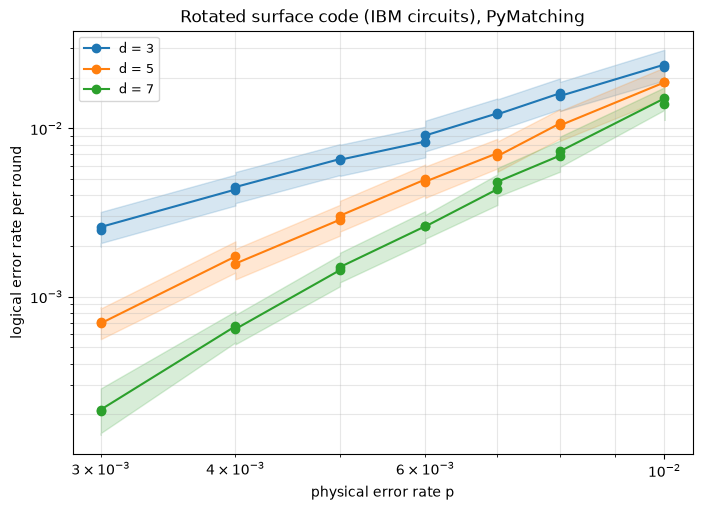

In [13]:
DISTANCES = [3, 5, 7]
NOISE     = [0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.01]

tasks = [sinter.Task(circuit=get_test_circuit("rotated_surface_code_memory_Z", distance=d, rounds=d, error_rate=p),
                     json_metadata={"d": d, "r": d, "p": p})
         for d in DISTANCES for p in NOISE]
surface = tour.collect(tasks, decoders=["pymatching"], max_shots=100_000, max_errors=300,
                       save_to="results/surface_pymatching.csv")

tour.plot_ler({f"d = {d}": [s for s in surface if s.json_metadata["d"] == d] for d in DISTANCES},
              "Rotated surface code (IBM circuits), PyMatching")
plt.show()

**What the graph shows.** At every noise level, a bigger distance gives a lower error rate, and the gap is
larger at low noise: at p = 0.003, going from d = 3 to d = 7 cuts the error per round about 10×. The lines get
closer as p rises but do not cross by p = 0.01, the highest noise IBM ships. So the threshold (where they
would cross) is above 1% for this circuit, noise model and decoder.

## Step 8 · Run: BB codes with Relay-BP

Now IBM's decoder on IBM's BB code circuits.

- **Codes:** [[18,4,3]] and [[72,12,6]] — the small members of the gross code's family. The gross code itself
  takes hours per point, so for it we use IBM's published numbers and our saved run instead (below).
- **Decoder:** Relay-BP with IBM's default settings, Z detectors only.
- **Shots:** stop at 20,000 shots or 200 failures per point. About 5 minutes on a laptop.

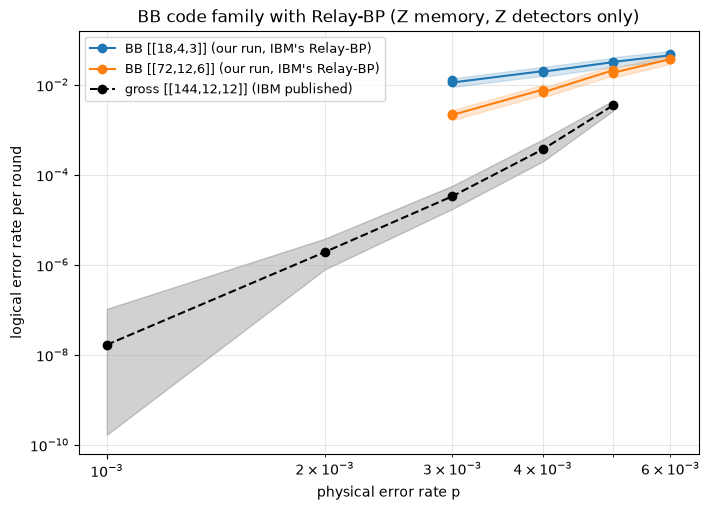

In [14]:
BB_CODES = {"[[18,4,3]]": ("bicycle_bivariate_18_4_3_memory_Z", 3),
            "[[72,12,6]]": ("bicycle_bivariate_72_12_6_memory_Z", 6)}
NOISE = [0.003, 0.004, 0.005, 0.006]

tasks = [sinter.Task(circuit=filter_detectors_by_basis(get_test_circuit(name, distance=d, rounds=d, error_rate=p), "Z"),
                     json_metadata={"code": label, "d": d, "r": d, "p": p})
         for label, (name, d) in BB_CODES.items() for p in NOISE]
bb = tour.collect(tasks, decoders=["relay-bp"], max_shots=20_000, max_errors=200, save_to="results/bb_relay.csv")

which = "IBM's Relay-BP" if tour.relay_installed() else "stabilizer-qec's Relay-BP"
series = {f"BB {c} (our run, {which})": [s for s in bb if s.json_metadata["code"] == c] for c in BB_CODES}
series["gross [[144,12,12]] (IBM published)"] = tour.select(ibm_gross, decoder="relay-bp", basis="Z", xyz=False)
tour.plot_ler(series, "BB code family with Relay-BP (Z memory, Z detectors only)",
              styles={"gross [[144,12,12]] (IBM published)": {"linestyle": "--", "color": "black"}})
tour.savefig("bb_family_relay.png"); plt.show()

**What the graph shows.** Larger members of the family protect better: at the same noise the [[72,12,6]]
code fails less per round than [[18,4,3]], and the gross code (IBM's data) less again.

### The gross code: our BP-OSD run against IBM's published numbers

Our gross code run (details in notebook 02) used IBM's circuits, the Z-detector filter and BP-OSD with IBM's
settings. Here it is next to IBM's own BP-OSD and Relay-BP results. Both are failure probability per
round (any of the 12 logical qubits).

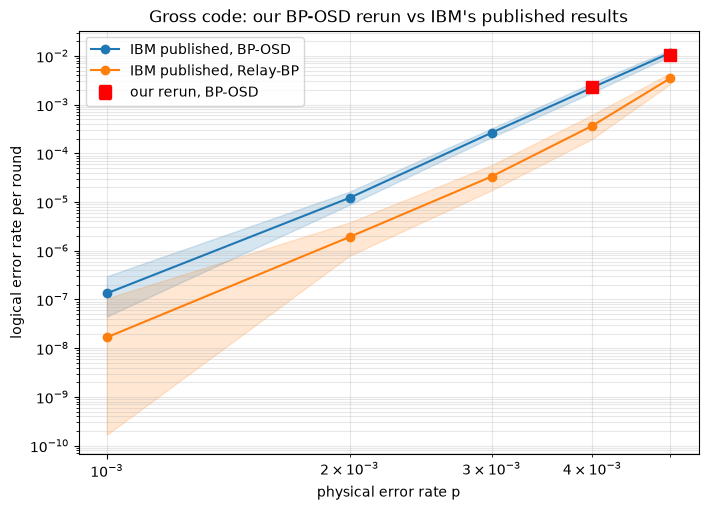

In [15]:
import pandas as pd
ours = pd.read_csv("data/results_gross.csv")
ours = ours[ours.circuit == "ibm"]           # our run on IBM's own circuits

ax = tour.plot_ler({
    "IBM published, BP-OSD": tour.select(ibm_gross, decoder="bp-osd", basis="Z", xyz=False),
    "IBM published, Relay-BP": tour.select(ibm_gross, decoder="relay-bp", basis="Z", xyz=False),
}, "Gross code: our BP-OSD rerun vs IBM's published results")
per_round = 1 - (1 - ours.P_L_12rounds) ** (1 / 12)
lo = 1 - (1 - ours.ci_low) ** (1 / 12); hi = 1 - (1 - ours.ci_high) ** (1 / 12)
ax.errorbar(ours.p, per_round, yerr=[per_round - lo, hi - per_round], fmt="s", color="red",
            markersize=8, capsize=4, label="our rerun, BP-OSD")
ax.legend(); plt.show()

**What the graph shows.** Our red points sit on IBM's BP-OSD curve within the error bars: our pipeline
reproduces IBM's published numbers on IBM's circuits.

## Step 9 · What we take from this repo

| From IBM's repo | Where we use it |
|---|---|
| Gross code memory circuits (`tests/testdata/bicycle_bivariate/`) | the gross code runs (notebook 02) |
| `filter_detectors_by_basis` (Z detectors only) | copied into `helpers/ibm_filter.py`, used before every BP-OSD decode |
| Decoder settings (BP-OSD: min-sum, 80 iterations, OSD-CS order 10) | `helpers/decode_bposd.py` |
| Published results (`examples/data/*.csv`) | the check in Step 8 |
| Surface code circuits | the baseline in Step 7 |

**Sources:** IBM Relay-BP repo https://github.com/trmue/relay · Müller et al. arXiv:2506.01779 ·
Bravyi et al., *Nature* 627, 778 (2024), arXiv:2308.07915 · Stim: Gidney, *Quantum* 5, 497 (2021) ·
PyMatching: Higgott & Gidney, arXiv:2303.15933 · BP-OSD: Roffe et al., *PRR* 2, 043423 (2020).